Load diabetes data set into data frame

In [21]:
import pandas as pd

from sklearn import datasets

#Load features of diabetes dataset from sklearn datsets into a dataframe
diabetes= datasets.load_diabetes(return_X_y=False)
df=pd.DataFrame(diabetes.data,columns=diabetes.feature_names)
df['label']=diabetes.target
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,label
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


Split data into training and test data

In [22]:
num_training_examples=300
num_features=10

train_features=df.iloc[:num_training_examples,:num_features]
train_labels=df.iloc[:num_training_examples,num_features]
test_features=df.iloc[num_training_examples:,:num_features]
test_labels=df.iloc[num_training_examples:,num_features]

train_labels

0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
295     85.0
296     89.0
297     31.0
298    129.0
299     83.0
Name: label, Length: 300, dtype: float64

Fit regression model to training data and print regression coefficiants

In [23]:
#Linear Regression
from sklearn import linear_model
reg = linear_model.LinearRegression()

#Fit regression model to training data
reg.fit(train_features,train_labels)

#Print regression coefficiants
print("Regression coefficients: ",reg.coef_)

Regression coefficients:  [ -16.57338609 -254.66343751  560.9894609   278.90965232 -393.45557666
   97.08855335  -18.9842756   169.46616165  632.96847103  114.21833048]


Predict a single value and calculate deviation to actual value

In [24]:
print("Predict label for following example: ",test_features.iloc[0,:])

#Predict a single value
predicted_value=reg.predict([test_features.iloc[0,:]])[0]

print("\nPredicted label: ",predicted_value)
print("Actual label:", test_labels.iloc[0])
print("Deviation predicted from actual value: ",predicted_value-test_labels.iloc[0])

Predict label for following example:  age    0.016281
sex   -0.044642
bmi    0.073552
bp    -0.041235
s1    -0.004321
s2    -0.013527
s3    -0.013948
s4    -0.001116
s5     0.042897
s6     0.044485
Name: 300, dtype: float64

Predicted label:  225.90361745261725
Actual label: 275.0
Deviation predicted from actual value:  -49.096382547382746


/Users/hendrikmeth/Python/PYTHON_DATA_SCIENCE/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Predict values for all test examples

In [25]:
#Predict all test examples
ypred = reg.predict(test_features)
ypred

array([225.90361745, 122.19508185, 206.98679522, 230.90247225,
       109.96202416, 127.94599697, 123.84826395, 146.52181459,
        88.9827528 , 140.36999951, 204.82939112, 173.94924617,
       122.27111051, 212.78573544, 174.59773091, 112.04466141,
       203.46579722, 169.5801066 , 163.82556572, 197.80878193,
       189.79711878, 290.18790978, 299.63055432, 231.31013144,
       209.57245912, 226.69701524, 156.33876468, 225.71306496,
       195.27849356, 103.03491298, 173.08310958, 110.33502923,
       293.97340987, 179.06814759,  77.55701088,  84.77346547,
       257.24228133, 166.97380517, 117.81605604, 149.09724803,
       163.43506812, 179.35362669, 158.91444084, 155.90543989,
       141.74041946, 121.56757939, 174.10130113, 103.35553809,
       133.91878591,  88.96809795, 257.04609851,  86.01608596,
        64.01560203, 177.44755356, 196.60331227, 132.22884644,
        87.57543376, 201.83550997,  52.90673405, 172.67013731,
       198.11119404, 122.24870679, 236.00415024, 161.76

# Evaluate model

Calculate MAE and R*R

In [26]:
from sklearn.metrics import mean_absolute_error

#Return Mean Absolute Error
mae = mean_absolute_error(test_labels, ypred)
print('MAE: %.3f' % mae)

#Return the coefficient of determination R^2 of the prediction.
print("R^2 value of the model: ",reg.score(test_features,test_labels))

MAE: 41.204
R^2 value of the model:  0.5071960134667436


Estimate p-values

In [27]:
####################### Calculate p-values with statsmodels package #######################
import statsmodels.api as sm
from scipy import stats

diabetes = datasets.load_diabetes()
X = train_features
y = train_labels

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                  label   R-squared:                       0.515
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     30.65
Date:                Tue, 18 Nov 2025   Prob (F-statistic):           5.92e-40
Time:                        10:21:19   Log-Likelihood:                -1622.7
No. Observations:                 300   AIC:                             3267.
Df Residuals:                     289   BIC:                             3308.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        152.3478      3.196     47.671      0.0

In [29]:
####################### Alternative: Calculate p-values without statsmodels package #######################

import numpy as np
from scipy import stats

X= test_features
y= test_labels

# Predictions and residuals
y_pred = ypred
residuals = y - y_pred

# Degrees of freedom
n, k = X.shape
df = n - k

# Residual variance
residual_var = np.sum(residuals ** 2) / df

# Add intercept term if model includes intercept
if reg.fit_intercept:
    X_design = np.column_stack((np.ones(n), X))
    coef = np.insert(reg.coef_, 0, reg.intercept_)
    feature_names = ['Intercept'] + list(X.columns)
else:
    X_design = X
    coef = reg.coef_

# Variance-Covariance matrix of beta (use X_design to include intercept)
XTX_inv = np.linalg.inv(X_design.T @ X_design)
var_beta = residual_var * XTX_inv

# Standard errors of coefficients
se_beta = np.sqrt(np.diag(var_beta))

# t-statistics
t_stats = coef / se_beta

# p-values from t-distribution (two-tailed)
p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df))

# Display the results
results = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef,
    'Standard Error': se_beta,
    't-Statistic': t_stats,
    'p-Value': p_values
})

results


,Feature,Coefficient,Standard Error,t-Statistic,p-Value
0,Intercept,152.347796,4.667125,32.642748,0.000000
1,age,-16.573386,115.475157,-0.143523,0.886096
2,sex,-254.663438,109.590525,-2.323772,0.021666
3,bmi,560.989461,115.760956,4.846103,0.000003
4,bp,278.909652,112.374842,2.481958,0.014322
5,s1,-393.455577,711.207071,-0.553222,0.581047
6,s2,97.088553,552.504325,0.175725,0.860780
7,s3,-18.984276,379.285128,-0.050053,0.960156
8,s4,169.466162,294.791735,0.574867,0.566359
9,s5,632.968471,320.086942,1.977489,0.050070


Check normality of error terms

<Axes: >

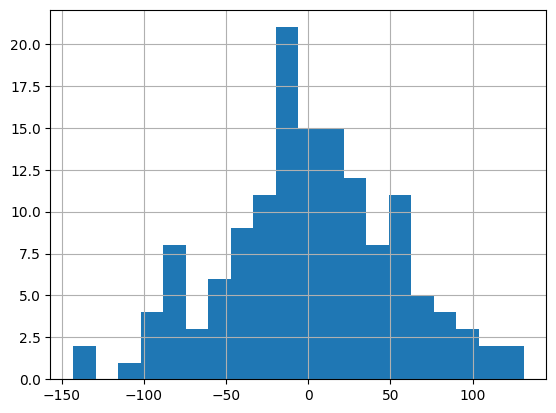

In [15]:
deviation = ypred-test_labels
deviation.hist(bins=20)

Create polynomial regression model for comparison

In [16]:
#Compare to polynomial regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

#Initialize and fit polynomial regression
degree=2
poly_reg=make_pipeline(PolynomialFeatures(degree),linear_model.LinearRegression())
poly_reg.fit(train_features,train_labels)

#Predict all test examples
ypred = poly_reg.predict(test_features)

mae = mean_absolute_error(test_labels, ypred)
print('MAE: %.3f' % mae)

MAE: 44.993


Create KNN regression model for comparison

In [17]:
from sklearn.neighbors import KNeighborsRegressor

#Initialize and fit KNN regression
KNN_reg = KNeighborsRegressor(n_neighbors=10)
KNN_reg.fit(train_features,train_labels)

#Predict all test examples
ypred = KNN_reg.predict(test_features)

mae = mean_absolute_error(test_labels, ypred)
print('MAE: %.3f' % mae)

MAE: 40.989


Create regression tree for comparison

In [18]:
from sklearn.tree import DecisionTreeRegressor

#Initialize and fit regression tree
tree_reg = DecisionTreeRegressor(random_state=0,max_depth=3)
tree_reg.fit(train_features,train_labels)

#Predict all test examples
ypred = tree_reg.predict(test_features)

mae = mean_absolute_error(test_labels, ypred)
print('MAE: %.3f' % mae)

MAE: 49.570
